Práctica 2 por Iván Pareja López

# PRÁCTICA 2

In [ ]:
import tensorflow as tf
print(tf.__version__)

2.20.0


In [ ]:
import numpy as np
import random


SEMILLA = 67
tf.random.set_seed(SEMILLA)

random.seed(SEMILLA)
np.random.seed(SEMILLA)

## Conjunto de datos
Para comenzar, utilizaremos un clásico conjunto de datos denominado [MNIST](http://yann.lecun.com/exdb/mnist/), formado por un conjunto de imágenes de dígitos manuscritos
![images](https://storage.googleapis.com/tfds-data/visualization/fig/mnist-3.0.1.png)

# Ejemplo de procedimiento que seguirmeos

In [ ]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

Para poder distinguir entre pares o impares, combertimos las etiquetas númericas a binarias:




In [ ]:
y_train = y_train % 2
y_test = y_test % 2

El conjunto de entrenamiento está formado por 60.000 imágenes de 28x28, mientras que el de test lo forman 10.000 imágenes. El problema de clasificación consiste en distinguir entre los 10 dígitos diferentes

In [ ]:
print("Datos de entrenamiento", x_train.shape)
print("Datos de test", x_test.shape)
print("Primeros dígitos: ", y_train[:5])

Datos de entrenamiento (60000, 28, 28)
Datos de test (10000, 28, 28)
Primeros dígitos:  [1 0 0 1 1]


## Pre-procesamiento
Como suele ser habitual, es conveniente realizar algún tipo de procesamiento antes de que los datos sean tratados por el modelo. En este caso, haremos un pequeño procesamiento que consiste en escalar los valores entre 0 y 1. Para ello, bastará con dividir por 255, ya que cada pixel de las imágenes de entrada viene representado por un entero entre 0 y 255 (8 bits) indicando su tonalidad de gris.

In [ ]:
x_train = x_train / 255.0
x_test = x_test / 255.0
x_train.dtype

dtype('float64')

## Modelo


In [ ]:
model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(2, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## Entrenamiento

In [ ]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:
h=model.fit(x_train, y_train, epochs=10)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9603 - loss: 0.1095
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9816 - loss: 0.0528
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9875 - loss: 0.0371
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9911 - loss: 0.0272
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9937 - loss: 0.0199
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9948 - loss: 0.0150
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9963 - loss: 0.0115
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9968 - loss: 0.0097
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9974 - loss: 0.0077
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9972 - loss: 0.0079


## Evaluación


In [ ]:
model.evaluate(x_train, y_train)
model.evaluate(x_test, y_test)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9983 - loss: 0.0054
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9891 - loss: 0.0501


[0.05010686442255974, 0.9890999794006348]

# Función para mostrar el resultado del modelo entrenado y testeado:

In [ ]:
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import pandas as pd
# Lista global para guardar los resultados de todos los experimentos
historial_experimentos = []


def evaluar_modelo(
    modelo,
    x_train,
    y_train,
    x_test,
    y_test,
    tiempo_entrenamiento,
    nombre_experimento="Experimento",
):
  """Calcula, muestra y retorna exactitud, número de errores y matrices de confusión

  tanto para entrenamiento como para test. Es compatible con Sigmoide (1 salida)
  y Softmax (2 salidas).
  """
  print(f" Tiempo de entrenamiento: {tiempo_entrenamiento:.2f} segundos\n")

  # 1. Obtener predicciones en crudo
  raw_train = modelo.predict(x_train, verbose=0)
  raw_test = modelo.predict(x_test, verbose=0)

  # 2. Detección automática: ¿Sigmoide (1 neurona) o Softmax (2 neuronas)?
  if raw_test.shape[-1] == 1:
    pred_train = (raw_train >= 0.5).astype(int).flatten()
    pred_test = (raw_test >= 0.5).astype(int).flatten()
  else:
    pred_train = np.argmax(raw_train, axis=1)
    pred_test = np.argmax(raw_test, axis=1)

  # 3. Métricas de Entrenamiento
  acc_train = np.mean(pred_train == y_train)
  errores_train = int(np.sum(pred_train != y_train))
  cm_train = confusion_matrix(y_train, pred_train)

  # 4. Métricas de Test
  acc_test = np.mean(pred_test == y_test)
  errores_test = int(np.sum(pred_test != y_test))
  cm_test = confusion_matrix(y_test, pred_test)

  # 5. Resumen en texto
  print("=" * 55)
  print(f" RESULTADOS: {nombre_experimento}")
  print("=" * 55)
  print(f" ENTRENAMIENTO:")
  print(f"   - Accuracy: {acc_train:.4%}")
  print(f"   - Errores:  {errores_train} de {len(y_train)}")
  print(f" TEST:")
  print(f"   - Accuracy: {acc_test:.4%}")
  print(f"   - Errores:  {errores_test} de {len(y_test)}")
  print("=" * 55 + "\n")

  # 6. Gráficas de Matrices de Confusión con etiquetas Par / Impar
  clases = ["Par (0)", "Impar (1)"]
  fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

  sns.heatmap(
      cm_train,
      annot=True,
      fmt="d",
      cmap="Blues",
      ax=axes[0],
      cbar=False,
      xticklabels=clases,
      yticklabels=clases,
  )
  axes[0].set_title(f"Train (Errores: {errores_train})")
  axes[0].set_xlabel("Predicción")
  axes[0].set_ylabel("Clase Real")

  sns.heatmap(
      cm_test,
      annot=True,
      fmt="d",
      cmap="Oranges",
      ax=axes[1],
      cbar=False,
      xticklabels=clases,
      yticklabels=clases,
  )
  axes[1].set_title(f"Test (Errores: {errores_test})")
  axes[1].set_xlabel("Predicción")
  axes[1].set_ylabel("Clase Real")

  plt.tight_layout()
  plt.show()

  # 7. Guardar en historial
  resultado = {
      "Experimento": nombre_experimento,
      "Tiempo (s)": round(tiempo_entrenamiento, 2),
      "Acc Train (%)": round(acc_train * 100, 2),
      "Errores Train": errores_train,
      "Acc Test (%)": round(acc_test * 100, 2),
      "Errores Test": errores_test,
  }
  historial_experimentos.append(resultado)
  return resultado

## EXPERIMENTOS:

# EXPERIMENTO 1: Softmax con sparse_categorical_crossentropy

Podemos pensar este problema como un problema multiclase C = 2 excluyentes (0 = par, 1 = impar), por lo que podemos usar Softmax que entrega una distribución de probabilidad normalizada $[P(\text{par}), P(\text{impar})]$ cuya suma es 1:

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


 Tiempo de entrenamiento: 58.44 segundos

 RESULTADOS: SoftMax
 ENTRENAMIENTO:
   - Accuracy: 99.5633%
   - Errores:  262 de 60000
 TEST:
   - Accuracy: 98.6400%
   - Errores:  136 de 10000



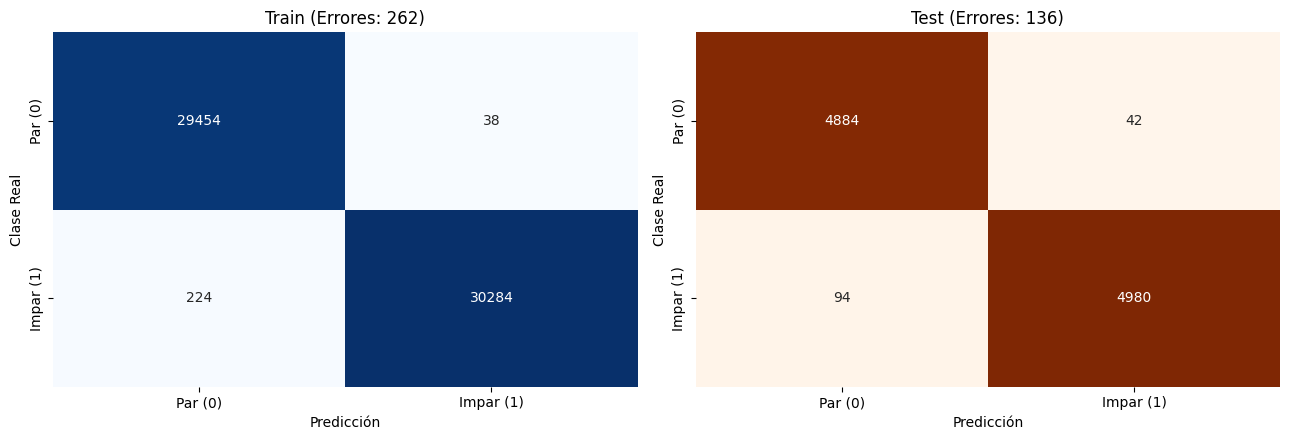

In [ ]:
model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(2, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


inicio = time.time()
h = model.fit(x_train, y_train, epochs=10, verbose=0)
tiempo_Softmax = time.time() - inicio

_ = evaluar_modelo(model, x_train, y_train, x_test, y_test, tiempo_Softmax, "SoftMax")

# EXPERIMENTO CON SIGMOIDE EN VEZ DE SOFTMAX

Con dos clases, la probabilidad asignada por una función Softmax es idéntica a la calculada por una Sigmoide si usamos binary_crossentropy, y de hecho será algo más eficiente porque requiere calcular un solo valor y hacer la mitad de las operaciones de multiplicación en la capa de salida en comparación con Softmax.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


 Tiempo de entrenamiento: 63.10 segundos

 RESULTADOS: Sigmoide
 ENTRENAMIENTO:
   - Accuracy: 99.4433%
   - Errores:  334 de 60000
 TEST:
   - Accuracy: 98.6100%
   - Errores:  139 de 10000



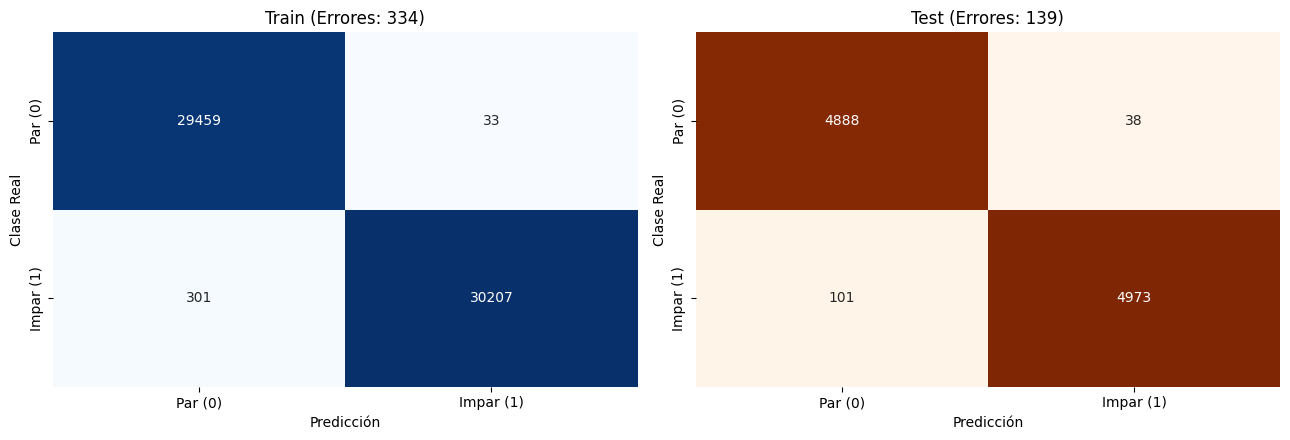

In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid'),
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)


inicio = time.time()
h = model.fit(x_train, y_train, epochs=10, verbose=0)
tiempo_Sigmoide = time.time() - inicio

_ = evaluar_modelo(model, x_train, y_train, x_test, y_test, tiempo_Sigmoide, "Sigmoide")

Podemos comprobar que hemos obtenido resultados muy parecidos (probablemente debido al azar del entrenamiento), aunque como predijimos, la Sigmoide ha tardado menos tiempo al ser más eficiente

# SOFTMAX CON DROPOUT

El dropout es muy probable que mejore el rendimiento (sobre todo en el test) porque actúa como regularizador, evitando sobreajuste y rompiendo la co-adaptación, por lo que esperamos mejores resultados:

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


 Tiempo de entrenamiento: 69.34 segundos

 RESULTADOS: Softmax con Dropout
 ENTRENAMIENTO:
   - Accuracy: 99.5817%
   - Errores:  251 de 60000
 TEST:
   - Accuracy: 98.7800%
   - Errores:  122 de 10000



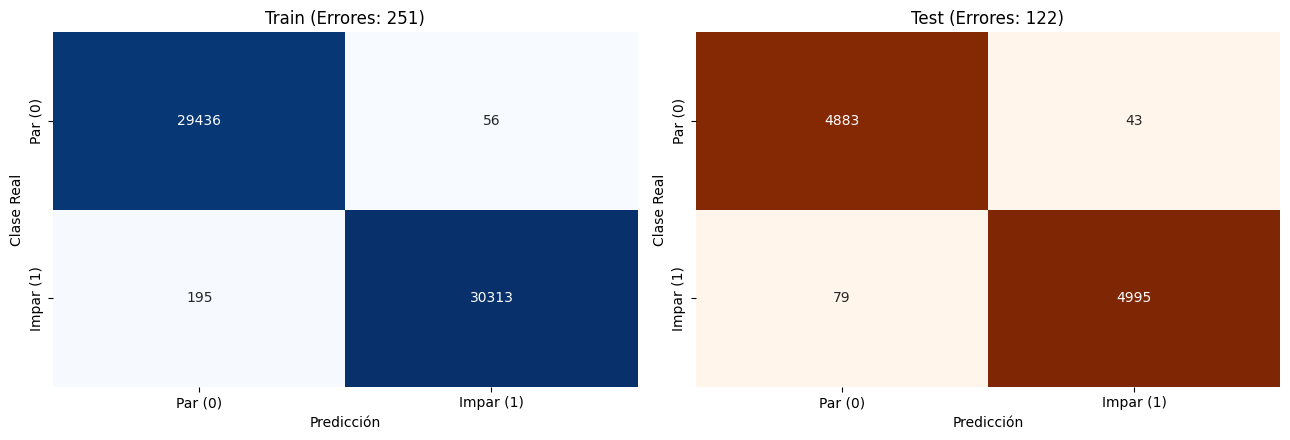

In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(2, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


inicio = time.time()
h = model.fit(x_train, y_train, epochs=10, verbose=0)
tiempo_Softmax_Dropout = time.time() - inicio

_ = evaluar_modelo(model, x_train, y_train, x_test, y_test, tiempo_Softmax_Dropout, "Softmax con Dropout")

# SIGMOIDE CON DROPOUT

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


 Tiempo de entrenamiento: 64.87 segundos

 RESULTADOS: Sigmoide con Dropout
 ENTRENAMIENTO:
   - Accuracy: 99.7050%
   - Errores:  177 de 60000
 TEST:
   - Accuracy: 98.6800%
   - Errores:  132 de 10000



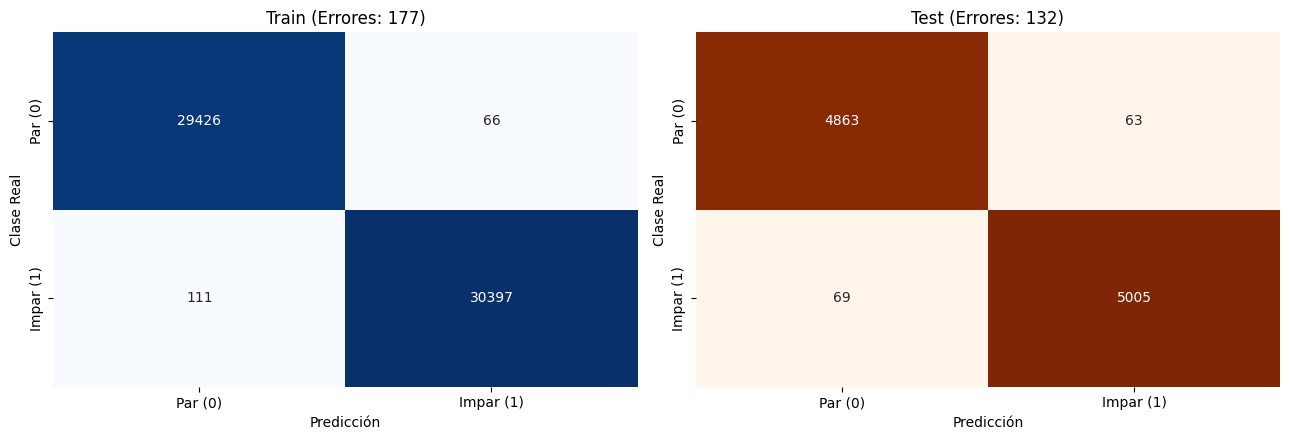

In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation='sigmoid'),
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)


inicio = time.time()
h = model.fit(x_train, y_train, epochs=10, verbose=0)
tiempo_Sigmoide_Dropout = time.time() - inicio

_ = evaluar_modelo(model, x_train, y_train, x_test, y_test, tiempo_Sigmoide_Dropout, "Sigmoide con Dropout")

También ha mejorado el modelo con sigmoide

# Añadiendo una capa a la mejor Softmax (con Dropout)

Añadir más capas teoricamente mejorará la capacidad de computación de la red y ayudará a aprender patrones más complejos, aunque con la posibilidad de mayor sobreajuste o subajuste si le faltan épocas, además de ser mucho menos eficiente, añadiremos más tiempo de entrenamiento:

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


 Tiempo de entrenamiento: 71.67 segundos

 RESULTADOS: Softmax con mas capas
 ENTRENAMIENTO:
   - Accuracy: 99.5067%
   - Errores:  296 de 60000
 TEST:
   - Accuracy: 98.5500%
   - Errores:  145 de 10000



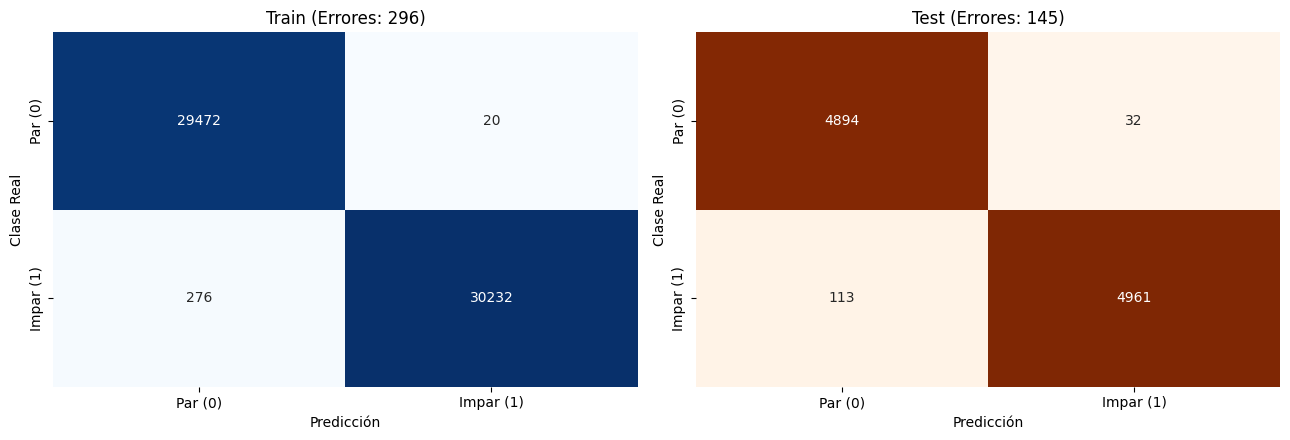

In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(2, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


inicio = time.time()
h = model.fit(x_train, y_train, epochs=10, verbose=0)
tiempo_Softmax_mas_capas = time.time() - inicio

_ = evaluar_modelo(model, x_train, y_train, x_test, y_test, tiempo_Softmax_mas_capas, "Softmax con mas capas")

Ha empeorado el modelo, probablemente debido a un sobreajuste, pues la capas intermedias no tienen ningún tipo de regularización y tenemos demasiada capacidad de cómputo para este problema

# Añadiendo capas a la mejor Sigmoide (con Dropout)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


 Tiempo de entrenamiento: 67.70 segundos

 RESULTADOS: Sigmoide con mas capas
 ENTRENAMIENTO:
   - Accuracy: 99.5933%
   - Errores:  244 de 60000
 TEST:
   - Accuracy: 98.7000%
   - Errores:  130 de 10000



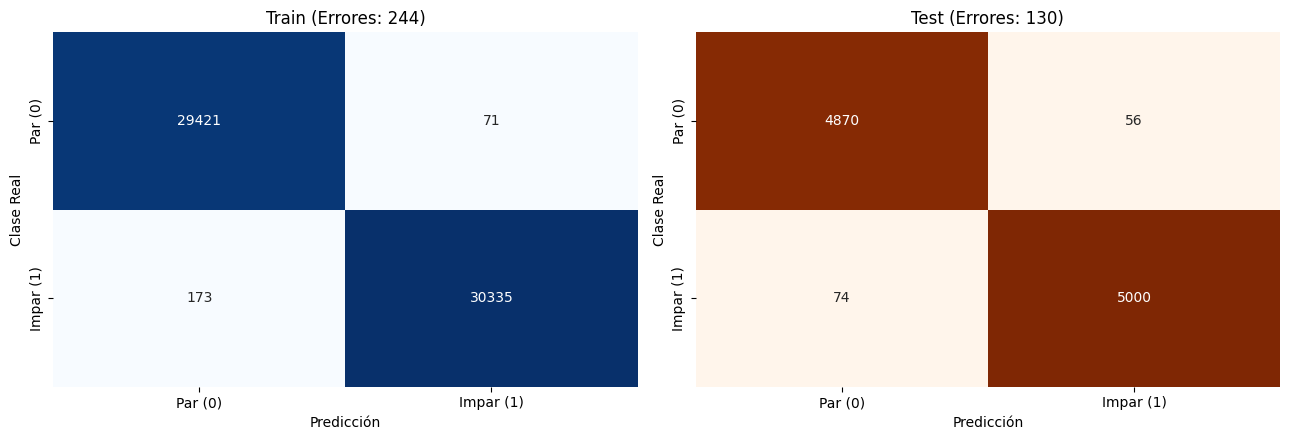

In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation='sigmoid'),
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)


inicio = time.time()
h = model.fit(x_train, y_train, epochs=10, verbose=0)
tiempo_Sigmoide_mas_capas = time.time() - inicio

_ = evaluar_modelo(model, x_train, y_train, x_test, y_test, tiempo_Sigmoide_mas_capas, "Sigmoide con mas capas")

Para la Sigmoide sí mejora algo el modelo, pero sigue estando por debajo de la Softmax con dropout

# Añadir dropout a todas las capas:

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


 Tiempo de entrenamiento: 70.73 segundos

 RESULTADOS: Softmax con todos los Dropout
 ENTRENAMIENTO:
   - Accuracy: 99.6583%
   - Errores:  205 de 60000
 TEST:
   - Accuracy: 98.9100%
   - Errores:  109 de 10000



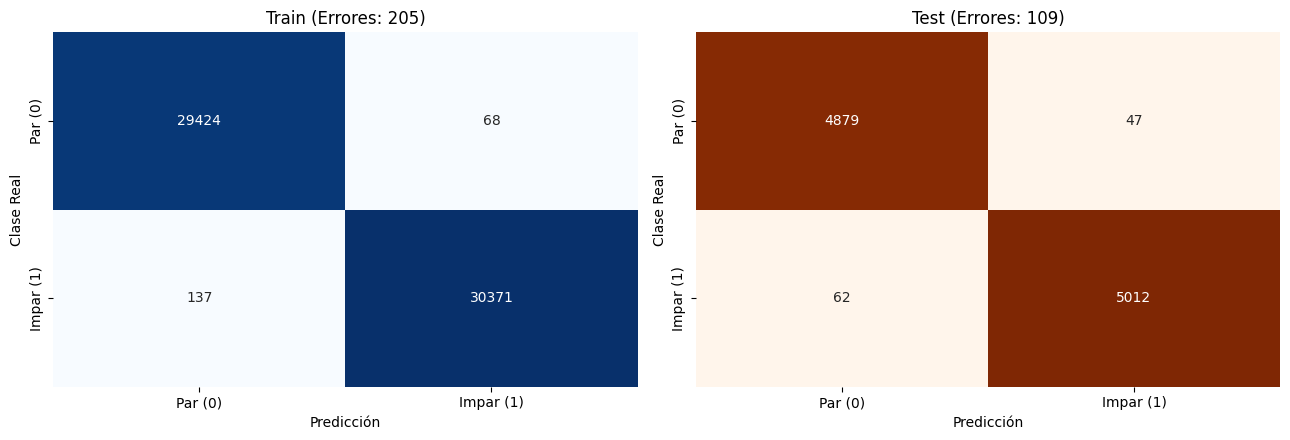

In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(2, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


inicio = time.time()
h = model.fit(x_train, y_train, epochs=10, verbose=0)
tiempo_Softmax_todos_dropout = time.time() - inicio

_ = evaluar_modelo(model, x_train, y_train, x_test, y_test, tiempo_Softmax_todos_dropout, "Softmax con todos los Dropout")

Hemos mejorado el modelo probablemente debido a que al aplicar regularización en todos los niveles de abstracción (hemos solucionado el problema que probocaba el sobreajuste en el otro experimento con más capas), las primeras capas se encargan de detectar patrones básicos (trazos, bordes y curvas en las imágenes). Si solo ponemos Dropout al final, las primeras capas pueden memorizar píxeles específicos o ruido del conjunto de entrenamiento. Al aplicarlo en todas las capas, fuerzas a que tanto los patrones iniciales como las representaciones más profundas sean robustas e independientes.

# Intentamos mejorar el mejor modelo cambiando algunos parámetros:

Probamos a aumentar el número de neuronas y aumentar el dropout

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


 Tiempo de entrenamiento: 185.23 segundos

 RESULTADOS: Softmax (256-128) con Dropout y 20 Epochs
 ENTRENAMIENTO:
   - Accuracy: 99.8150%
   - Errores:  111 de 60000
 TEST:
   - Accuracy: 98.8900%
   - Errores:  111 de 10000



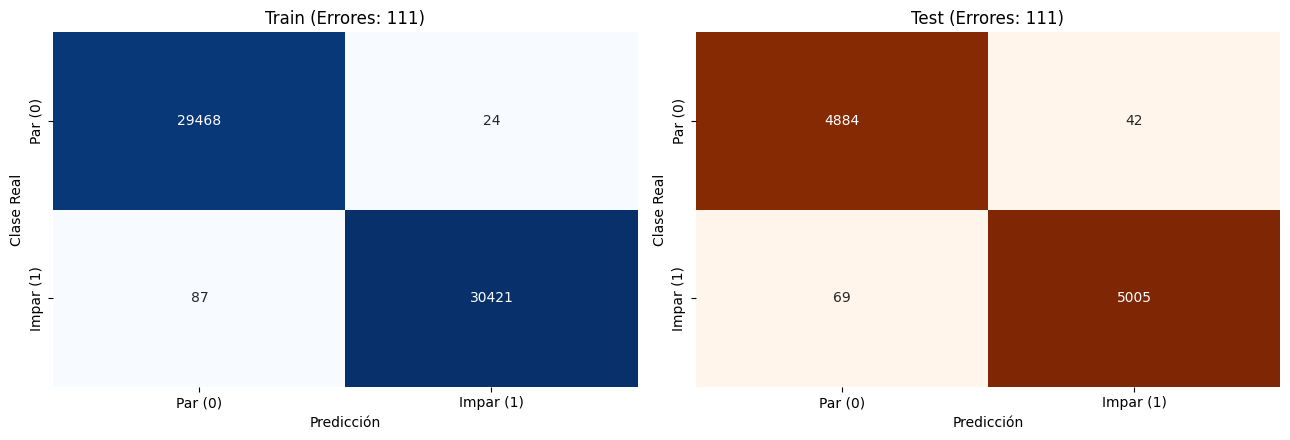

In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(2, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


inicio = time.time()
h = model.fit(x_train, y_train, epochs=20, verbose=0)
tiempo_Softmax_parametros = time.time() - inicio

_ = evaluar_modelo(model, x_train, y_train, x_test, y_test, tiempo_Softmax_parametros, "Softmax (256-128) con Dropout y 20 Epochs")

Hemos mejorado algo con respecto al modelo simple de Softmax con Dropout, (aunque no con respecto el anterior) porque, al añadirle mayor anchura, 256 neuornas frente a 128 en la primera capa, la red dispone de mucho más espacio para aprender detectores de trazos independientes para los diez dígitos distintos sin que compitan entre sí por los mismos pesos.

El Dropout al 40% (0.4), en una red más ancha y profunda corre un riesgo elevado de sobreajustarse y memorizar ruido. El Dropout de 0.4 actúa como un freno, desactivando casi la mitad de las conexiones en cada paso, forzando a que esa capacidad extra se traduzca en representaciones redundantes y robustas, no en memorización.

Probamos con leaky_relu por si en este caso obtenemos mejor resultado (aunque como vimos en la otra práctica, es probable que no):

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


 Tiempo de entrenamiento: 280.13 segundos

 RESULTADOS: Softmax con Leaky ReLU
 ENTRENAMIENTO:
   - Accuracy: 99.5483%
   - Errores:  271 de 60000
 TEST:
   - Accuracy: 98.5800%
   - Errores:  142 de 10000



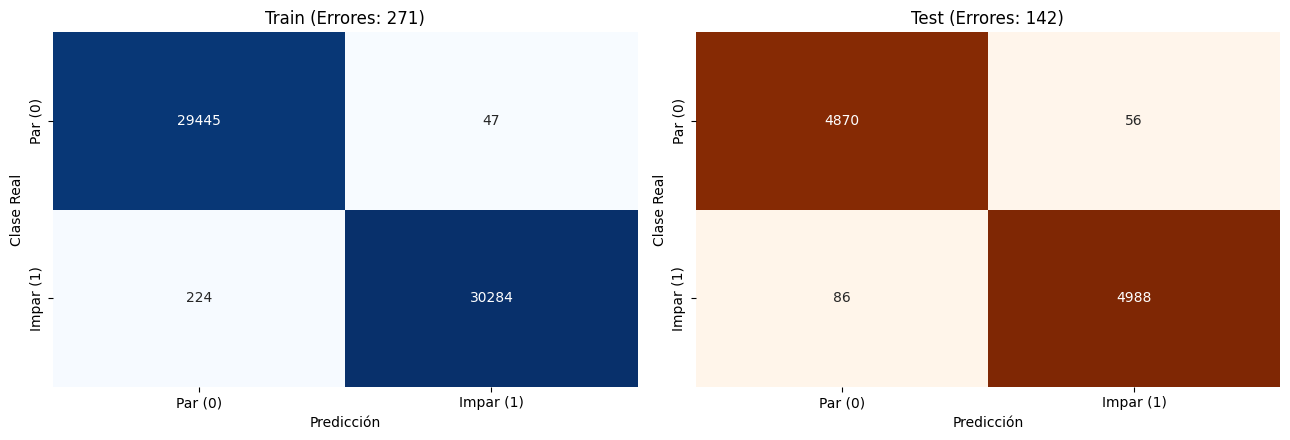

In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(256, activation=tf.nn.leaky_relu),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(2, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


inicio = time.time()
h = model.fit(x_train, y_train, epochs=30, verbose=0)
tiempo_Softmax_leaky = time.time() - inicio

_ = evaluar_modelo(model, x_train, y_train, x_test, y_test, tiempo_Softmax_leaky, "Softmax con Leaky ReLU")

Como suponíamos, volvemos a obtener un peor modelo como ya explicamos en la otra práctica, básicamente debido a que el objetivo de Leaky ReLU era evitar el problema de la neurona muerta. Sin embargo, para predecir los números, se colocan sobre un fondo blanco, por lo que Relu normal puede estar contribuyendo a eliminar el ruido del fondo de las imágenes apagando algunas neuronas que en Leaky ReLU ha podido quedar una pequeña cantidad de señal debido a que no se ha podido apagar la neurona.

# MEJOR MODELO: CAPAS ESTILO "EMBUDO"

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


 Tiempo de entrenamiento: 293.92 segundos

 RESULTADOS: Softmax estilo embudo
 ENTRENAMIENTO:
   - Accuracy: 99.8333%
   - Errores:  100 de 60000
 TEST:
   - Accuracy: 99.0500%
   - Errores:  95 de 10000



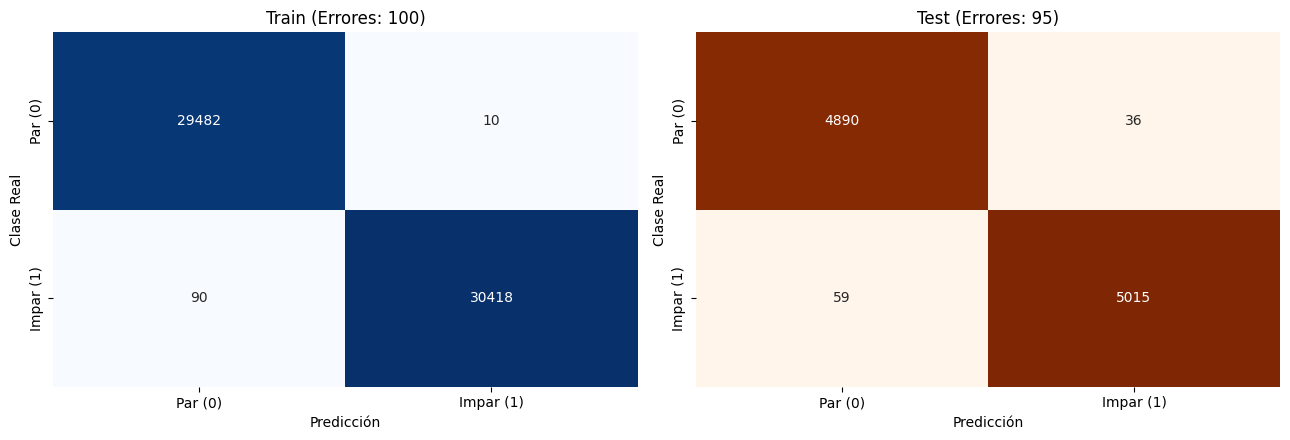

In [ ]:
mejor_modelo = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(2, activation='softmax')
])

mejor_modelo.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


inicio = time.time()
h = mejor_modelo.fit(x_train, y_train, epochs=20, verbose=0)
tiempo_Softmax_parametros = time.time() - inicio

_ = evaluar_modelo(mejor_modelo, x_train, y_train, x_test, y_test, tiempo_Softmax_parametros, "Softmax estilo embudo")

Con esto obtenemos el mejor resultado gracias a que esta transición gradual permite que la primera capa extraiga patrones visuales primarios ricos (bucles, rectas, cruces) y la segunda capa sintetice combinaciones más abstractas que separan con mayor nitidez la frontera entre par e impar antes de llegar al clasificador final.
Además, hemos proporcionado la cantidad de Dropout según el número de neuronas para que no sea excesivo.

# COMPARACIÓN FINAL PARA ENCONTRAR EL MEJOR MODELO

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convertimos el historial acumulado en un DataFrame de Pandas para su visualización
df_resultados = pd.DataFrame(historial_experimentos)

# Mostramos la tabla ordenada de mejor a peor según la precisión (Accuracy) de Test
print(" TABLA COMPARATIVA DE EXPERIMENTOS:")
display(df_resultados.sort_values(by="Acc Test (%)", ascending=False).reset_index(drop=True))

 TABLA COMPARATIVA DE EXPERIMENTOS:


,Experimento,Tiempo (s),Acc Train (%),Errores Train,Acc Test (%),Errores Test
0,Softmax estilo embudo,293.92,99.83,100,99.05,95
1,Softmax con todos los Dropout,70.73,99.66,205,98.91,109
2,Softmax (256-128) con Dropout y 20 Epochs,185.23,99.82,111,98.89,111
3,Softmax con Dropout,69.34,99.58,251,98.78,122
4,Sigmoide con mas capas,67.70,99.59,244,98.70,130
5,Sigmoide con Dropout,64.87,99.70,177,98.68,132
6,SoftMax,58.44,99.56,262,98.64,136
7,Sigmoide,63.10,99.44,334,98.61,139
8,Softmax con Leaky ReLU,280.13,99.55,271,98.58,142
9,Softmax con mas capas,71.67,99.51,296,98.55,145


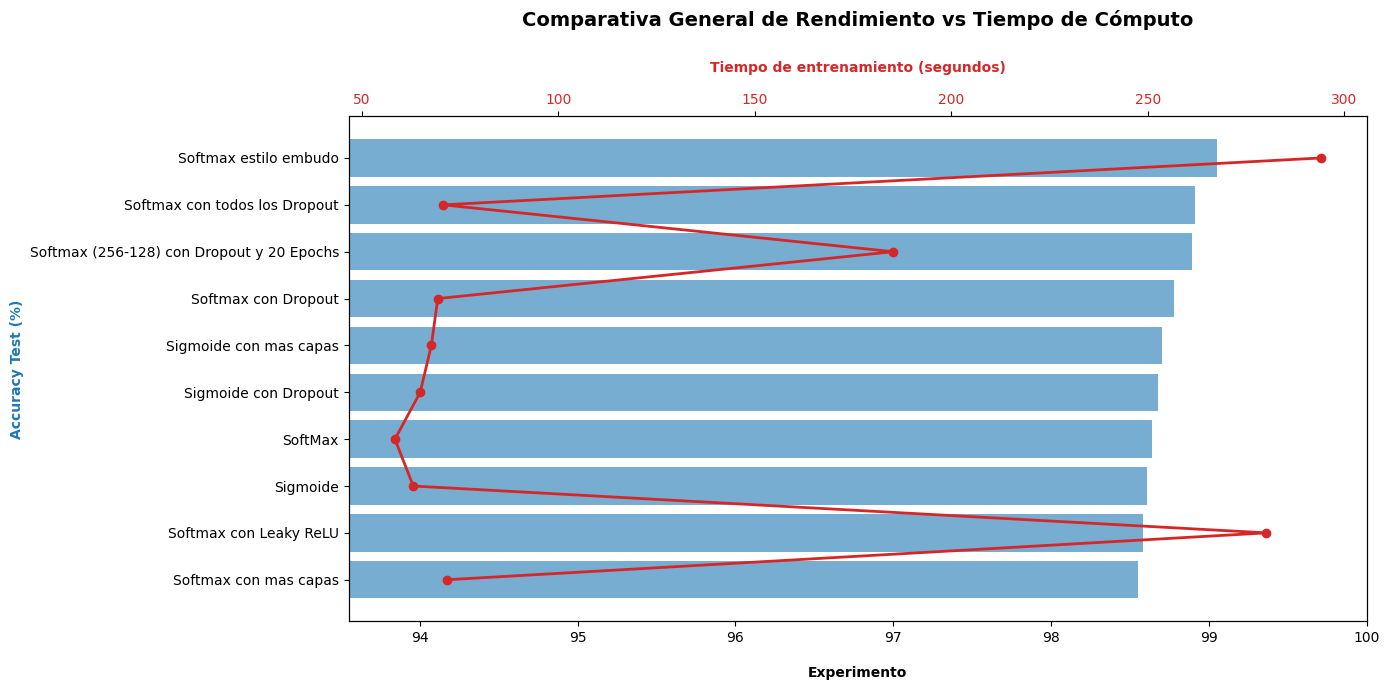

In [ ]:
# Generamos la gráfica comparativa
if not df_resultados.empty:
    fig, ax1 = plt.subplots(figsize=(14, 7))

    # Ordenamos para la representación gráfica
    df_plot = df_resultados.sort_values(by="Acc Test (%)", ascending=True)

    color = 'tab:blue'
    ax1.set_xlabel('Experimento', fontweight='bold', labelpad=15)
    ax1.set_ylabel('Accuracy Test (%)', color=color, fontweight='bold')
    bars = ax1.barh(df_plot['Experimento'], df_plot['Acc Test (%)'], color=color, alpha=0.6, label='Accuracy Test (%)')
    ax1.tick_params(axis='y')

    # Ajustamos el límite del eje X dinámicamente según la peor exactitud, para apreciar diferencias sutiles
    min_acc = df_plot['Acc Test (%)'].min()
    ax1.set_xlim(max(0, min_acc - 5), 100)

    # Creamos un eje gemelo para visualizar el impacto temporal
    ax2 = ax1.twiny()
    color = 'tab:red'
    ax2.set_xlabel('Tiempo de entrenamiento (segundos)', color=color, fontweight='bold', labelpad=15)
    ax2.plot(df_plot['Tiempo (s)'], df_plot['Experimento'], color=color, marker='o', linewidth=2, label='Tiempo (s)')
    ax2.tick_params(axis='x', labelcolor=color)

    plt.title('Comparativa General de Rendimiento vs Tiempo de Cómputo', fontsize=14, fontweight='bold', pad=25)
    fig.tight_layout()
    plt.show()
else:
    print(" El historial de experimentos está vacío. Asegúrate de volver a ejecutar las celdas de entrenamiento de los modelos modificados.")

Podemos ver en la gráfica cómo el mejor modelo es el modelo "Embudo", pero la Softmax con varias capas y dropout en todas las capas consigue un resultado muy parecido pero con un coste computacional mucho menor según podemos ver en la gráfica de tiempo.

# GUARDAMOS EL MEJOR MODELO:

In [ ]:
mejor_modelo.save('mejor_modelo_par_impar.keras')